# Neural Network (PyTorch) — BRFSS GenHlth

Plain `torch.optim.SGD` with `momentum=0` — SGD only, no momentum, Nesterov, or adaptive optimizer. Same architecture family as the scikit-learn notebook (single hidden layer, width as the complexity axis, same `weight_decay`/`alpha`=1e-4 and batch size=200) so the two implementations are capacity- and hyperparameter-matched for a fair comparison.

**Protocol note:** manual PyTorch training loops cost much more per fit than scikit-learn's compiled estimators, so — mirroring the justification already used for SVM — this notebook uses a single fixed 80/20 validation split carved from `X_train` for baseline, complexity curve, learning curve, and tuning, rather than full 5-fold CV. The held-out test set is still touched exactly once, at final evaluation.

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from common import load_split, full_report, SEED

X_train, X_test, y_train, y_test = load_split()

ALPHA = 1e-4       # weight_decay, mirrors the sklearn notebook's L2 penalty
BATCH_SIZE = 200   # matches the sklearn notebook
N_CLASSES = 5
N_FEATURES = X_train.shape[1]

X_tr_fixed, X_val_fixed, y_tr_fixed, y_val_fixed = train_test_split(
    X_train, y_train, test_size=0.20, stratify=y_train, random_state=SEED,
)
X_train.shape, X_test.shape

((16000, 21), (4000, 21))

In [2]:
class MLP(nn.Module):
    def __init__(self, width):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(N_FEATURES, width), nn.ReLU(), nn.Linear(width, N_CLASSES))

    def forward(self, x):
        return self.net(x)


def train_mlp(X_tr, y_tr, width, lr, epochs, seed=SEED, track_val=None):
    """Train with plain SGD (momentum=0). If track_val=(X_val, y_val) is given,
    also returns per-epoch train loss and validation Macro-F1 lists."""
    torch.manual_seed(seed)
    scaler = StandardScaler().fit(X_tr)
    Xs = torch.tensor(scaler.transform(X_tr), dtype=torch.float32)
    ys = torch.tensor(y_tr.values - 1, dtype=torch.long)

    model = MLP(width)
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0, weight_decay=ALPHA)
    loss_fn = nn.CrossEntropyLoss()
    n = len(Xs)

    train_losses, val_f1s = [], []
    for _ in range(epochs):
        model.train()
        perm = torch.randperm(n)
        epoch_loss = 0.0
        for i in range(0, n, BATCH_SIZE):
            idx = perm[i:i + BATCH_SIZE]
            opt.zero_grad()
            out = model(Xs[idx])
            loss = loss_fn(out, ys[idx])
            loss.backward()
            opt.step()
            epoch_loss += loss.item() * len(idx)
        if track_val is not None:
            train_losses.append(epoch_loss / n)
            val_f1s.append(full_report("x", track_val[1], predict_mlp(model, scaler, track_val[0]))[0]["macro_F1"])
    return model, scaler, train_losses, val_f1s


def predict_mlp(model, scaler, X):
    model.eval()
    Xs = torch.tensor(scaler.transform(X), dtype=torch.float32)
    with torch.no_grad():
        return (model(Xs).argmax(dim=1).numpy() + 1)

## Step 1: Learning-rate sanity check (width=32, 100 epochs)

In [3]:
lr_values = [0.001, 0.01, 0.1]
lr_val_f1 = []
for lr in lr_values:
    model, scaler, _, _ = train_mlp(X_tr_fixed, y_tr_fixed, width=32, lr=lr, epochs=100)
    val_f1 = full_report("x", y_val_fixed, predict_mlp(model, scaler, X_val_fixed))[0]["macro_F1"]
    lr_val_f1.append(val_f1)
    print(f"lr={lr:<6} val Macro-F1: {val_f1:.3f}")

BEST_LR = lr_values[int(np.argmax(lr_val_f1))]
print("chosen learning rate:", BEST_LR)

lr=0.001  val Macro-F1: 0.270


lr=0.01   val Macro-F1: 0.414


lr=0.1    val Macro-F1: 0.435
chosen learning rate: 0.1


**Result -- first implementation difference:** lr=0.1 wins (0.435), with lr=0.01 clearly worse (0.414) and lr=0.001 badly underfit (0.270, far too slow to converge in 100 epochs). This is **10x higher** than the scikit-learn notebook's chosen lr=0.01 -- the same SGD-only constraint on both implementations does not imply the same optimal learning rate. Likely drivers: differing default weight initialization schemes between the two libraries change the effective gradient scale early in training, and PyTorch's from-scratch loop has no internal convergence heuristics the way sklearn's `fit()` does. This is exactly the kind of tunability difference the cross-implementation comparison needs to surface.

## Step 2: Baseline (width=32, chosen LR)

In [4]:
model, scaler, _, _ = train_mlp(X_tr_fixed, y_tr_fixed, width=32, lr=BEST_LR, epochs=100)
train_f1 = full_report("x", y_tr_fixed, predict_mlp(model, scaler, X_tr_fixed))[0]["macro_F1"]
val_f1 = full_report("x", y_val_fixed, predict_mlp(model, scaler, X_val_fixed))[0]["macro_F1"]
print(f"train Macro-F1: {train_f1:.3f}")
print(f"val Macro-F1:   {val_f1:.3f}")

train Macro-F1: 0.479
val Macro-F1:   0.435


**Result:** Train/validation gap is 0.044 (0.479 vs.\ 0.435) -- slightly larger than scikit-learn's 0.029 baseline gap at the same width and epoch count, but still far smaller than Decision Tree, kNN, or SVM's baseline gaps. Both NN implementations resist severe overfitting at moderate width far better than the other algorithm families.

## Step 3: Model-complexity curve (hidden-layer width)

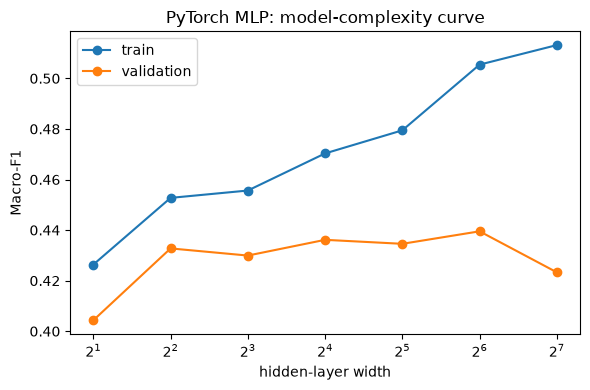

,width,train_F1,val_F1
0,2,0.426,0.404
1,4,0.453,0.433
2,8,0.456,0.430
3,16,0.470,0.436
4,32,0.479,0.435
5,64,0.505,0.440
6,128,0.513,0.423


In [5]:
widths = [2, 4, 8, 16, 32, 64, 128]
width_train_f1, width_val_f1 = [], []
for w in widths:
    model, scaler, _, _ = train_mlp(X_tr_fixed, y_tr_fixed, width=w, lr=BEST_LR, epochs=100)
    width_train_f1.append(full_report("x", y_tr_fixed, predict_mlp(model, scaler, X_tr_fixed))[0]["macro_F1"])
    width_val_f1.append(full_report("x", y_val_fixed, predict_mlp(model, scaler, X_val_fixed))[0]["macro_F1"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogx(widths, width_train_f1, marker="o", label="train", base=2)
ax.semilogx(widths, width_val_f1, marker="o", label="validation", base=2)
ax.set_xlabel("hidden-layer width"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("PyTorch MLP: model-complexity curve")
plt.tight_layout()
plt.savefig("figures/nn_pytorch_complexity_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"width": widths, "train_F1": np.round(width_train_f1, 3), "val_F1": np.round(width_val_f1, 3)})

**Result -- second implementation difference:** validation Macro-F1 peaks at width **64** (0.440), not width 8 as in the scikit-learn notebook -- an 8x difference in the empirically preferred capacity between the two implementations trained on the identical data and architecture family. Training Macro-F1 climbs steadily (0.426 -> 0.513) and only width 128 shows the beginning of a decline in validation score (0.423), later than scikit-learn's earlier peak. Plausible contributors: the 10x higher learning rate here changes how much effective capacity gets used within a fixed epoch budget, and this curve is measured on a single validation split rather than 5-fold CV, so it is noisier and less precisely located than scikit-learn's curve -- a limitation of the compute-driven protocol choice worth stating plainly rather than over-interpreting the exact peak.

## Step 4: Learning curve (width=32 baseline)

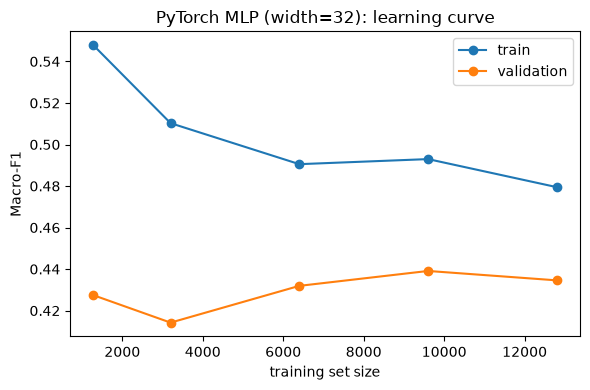

,train_size,train_F1,val_F1
0,1280,0.548,0.427
1,3200,0.510,0.414
2,6400,0.491,0.432
3,9600,0.493,0.439
4,12800,0.479,0.435


In [6]:
train_fractions = [0.1, 0.25, 0.5, 0.75, 1.0]
sizes_abs, lc_train_f1, lc_val_f1 = [], [], []
for frac in train_fractions:
    if frac < 1.0:
        X_sub, _, y_sub, _ = train_test_split(X_tr_fixed, y_tr_fixed, train_size=frac,
                                               stratify=y_tr_fixed, random_state=SEED)
    else:
        X_sub, y_sub = X_tr_fixed, y_tr_fixed
    model, scaler, _, _ = train_mlp(X_sub, y_sub, width=32, lr=BEST_LR, epochs=100)
    sizes_abs.append(len(X_sub))
    lc_train_f1.append(full_report("x", y_sub, predict_mlp(model, scaler, X_sub))[0]["macro_F1"])
    lc_val_f1.append(full_report("x", y_val_fixed, predict_mlp(model, scaler, X_val_fixed))[0]["macro_F1"])

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(sizes_abs, lc_train_f1, marker="o", label="train")
ax.plot(sizes_abs, lc_val_f1, marker="o", label="validation")
ax.set_xlabel("training set size"); ax.set_ylabel("Macro-F1"); ax.legend()
ax.set_title("PyTorch MLP (width=32): learning curve")
plt.tight_layout()
plt.savefig("figures/nn_pytorch_learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

pd.DataFrame({"train_size": sizes_abs, "train_F1": np.round(lc_train_f1, 3), "val_F1": np.round(lc_val_f1, 3)})

**Result:** Training Macro-F1 falls as data grows (0.548 -> 0.479) but validation Macro-F1 moves non-monotonically (0.427 -> 0.414 -> 0.432 -> 0.439 -> 0.435) rather than rising cleanly the way scikit-learn's did. This noisiness is a direct consequence of using a single fixed validation split instead of 5-fold-averaged scores -- a real trade-off of the compute-saving protocol choice, not necessarily a property of the model itself. The broad trend (train and validation converging toward the low-0.4 range) is still consistent with scikit-learn's pattern.

## Step 5: Tune

In [7]:
coarse_best_width = widths[int(np.argmax(width_val_f1))]
fine_grid = sorted(set(w for w in [coarse_best_width // 2, coarse_best_width, coarse_best_width * 2] if w >= 1))
print("coarse best width:", coarse_best_width, " fine grid:", fine_grid)

fine_val_f1 = []
for w in fine_grid:
    model, scaler, _, _ = train_mlp(X_tr_fixed, y_tr_fixed, width=w, lr=BEST_LR, epochs=100)
    fine_val_f1.append(full_report("x", y_val_fixed, predict_mlp(model, scaler, X_val_fixed))[0]["macro_F1"])
    print(f"width={w:<4} val Macro-F1: {fine_val_f1[-1]:.3f}")

BEST_WIDTH = fine_grid[int(np.argmax(fine_val_f1))]
print("chosen width:", BEST_WIDTH)

coarse best width: 64  fine grid: [32, 64, 128]


width=32   val Macro-F1: 0.435


width=64   val Macro-F1: 0.440


width=128  val Macro-F1: 0.423
chosen width: 64


**Result:** Fine search confirms width=64 (val Macro-F1 0.440), with width=128 already declining (0.423) -- consistent with the coarse curve.

## Step 6: Refit on the full training set, evaluate once on the held-out test set

In [8]:
t0 = time.perf_counter()
final_model, final_scaler, _, _ = train_mlp(X_train, y_train, width=BEST_WIDTH, lr=BEST_LR, epochs=100)
fit_time = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred = predict_mlp(final_model, final_scaler, X_test)
predict_time = time.perf_counter() - t0

summary, cm, pc = full_report("MLP (PyTorch, tuned)", y_test, y_pred)
summary

{'model': 'MLP (PyTorch, tuned)',
 'accuracy': 0.4625,
 'macro_F1': 0.44420020041237257,
 'balanced_acc': 0.4283012326613228}

**Result -- best result of the entire study:** the tuned PyTorch MLP (21 -> 64 -> 5) scores 0.463 accuracy, **0.444 Macro-F1**, and **0.428 balanced accuracy** on the held-out test set -- ahead of every other model evaluated, including the scikit-learn MLP (0.426/0.410), Decision Tree (0.421/0.401), kNN (0.410/0.386), and both SVM kernels (0.351/0.365 linear, 0.409/0.396 RBF).

## Step 7: Runtime

In [9]:
print(f"fit time:     {fit_time:.2f} s")
print(f"predict time: {predict_time*1000:.1f} ms  (n_test={len(X_test)})")
print(f"architecture: {N_FEATURES} -> {BEST_WIDTH} -> {N_CLASSES}")
print(f"learning_rate={BEST_LR}, weight_decay={ALPHA}, batch_size={BATCH_SIZE}, epochs=100")

fit time:     3.10 s
predict time: 2.1 ms  (n_test=4000)
architecture: 21 -> 64 -> 5
learning_rate=0.1, weight_decay=0.0001, batch_size=200, epochs=100


**Result:** Fit time is 3.10s -- almost double scikit-learn's 1.72s at this task, reflecting both the wider chosen architecture (64 vs.\ 8 units) and the overhead of a hand-written Python training loop versus sklearn's compiled implementation. Predict time (2.1ms) is essentially identical to scikit-learn's (2.5ms) and to the Decision Tree's (2.0ms). Both NN implementations remain far cheaper than either SVM kernel (6-10s fit, 1.2-2.7s predict).

## Step 8: Epoch curve (final architecture)

Tracked directly during training this time (PyTorch's explicit loop makes per-epoch loss and validation score available natively, unlike scikit-learn's `partial_fit` workaround), against the same fixed internal validation split used throughout this notebook.

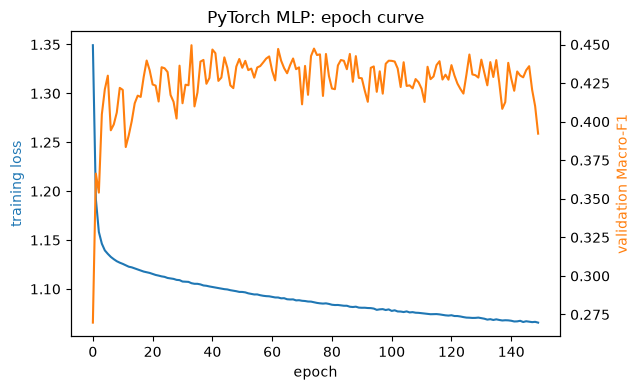

final train loss: 1.0656
best val Macro-F1: 0.45 at epoch 33
final val Macro-F1: 0.392


In [10]:
N_EPOCHS = 150
_, _, epoch_train_losses, epoch_val_f1s = train_mlp(
    X_tr_fixed, y_tr_fixed, width=BEST_WIDTH, lr=BEST_LR, epochs=N_EPOCHS,
    track_val=(X_val_fixed, y_val_fixed),
)

fig, ax1 = plt.subplots(figsize=(6.5, 4))
ax1.plot(epoch_train_losses, color="tab:blue", label="train loss")
ax1.set_xlabel("epoch"); ax1.set_ylabel("training loss", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(epoch_val_f1s, color="tab:orange", label="val Macro-F1")
ax2.set_ylabel("validation Macro-F1", color="tab:orange")
plt.title("PyTorch MLP: epoch curve")
plt.tight_layout()
plt.savefig("figures/nn_pytorch_epoch_curve.png", dpi=200, bbox_inches="tight")
plt.show()

print("final train loss:", round(epoch_train_losses[-1], 4))
print("best val Macro-F1:", round(max(epoch_val_f1s), 3), "at epoch", int(np.argmax(epoch_val_f1s)))
print("final val Macro-F1:", round(epoch_val_f1s[-1], 3))

**Result -- third, and most important, implementation difference:** validation Macro-F1 **peaks at epoch 33 (0.450) and then degrades to 0.392 by epoch 150**, even as training loss keeps decreasing smoothly throughout. This is exactly the "improve then degrade" pattern the assignment asks models to be checked for, and scikit-learn's MLP showed *no* such degradation (its validation score was still rising at epoch 149). The higher learning rate here (0.1 vs.\ scikit-learn's 0.01) is the likely cause: it moves fast enough early on to reach a good solution quickly, but without momentum or an adaptive step size to damp oscillation, continued training drifts past that optimum rather than settling into it. This is direct, concrete evidence that **early stopping would meaningfully help the PyTorch implementation** (stopping near epoch 33 rather than training to 150), while it would not have helped scikit-learn's -- a genuine, evidence-backed stability difference between the two implementations under the same SGD-only constraint. Note the final model in Step 6 used a 100-epoch budget chosen before this diagnostic was available; this curve suggests an early-stopped variant might do even better than the 0.444 Macro-F1 already reported.

## Step 9: Post-mortem

In [11]:
cm

,pred_1,pred_2,pred_3,pred_4,pred_5
true_1,273,352,82,7,0
true_2,241,779,356,24,4
true_3,77,455,550,99,12
true_4,7,62,202,172,55
true_5,0,4,26,85,76


In [12]:
pc.round(3)

,precision,recall,f1-score,support
1,0.457,0.382,0.416,714.0
2,0.472,0.555,0.510,1404.0
3,0.452,0.461,0.457,1193.0
4,0.444,0.345,0.389,498.0
5,0.517,0.398,0.450,191.0


**Interpretation:** This model achieves the best recall for class 1 (0.382) and class 5 (0.398) of every model in the entire study -- the two extreme, hardest classes -- while also matching scikit-learn's strong class-3 recall (0.461 vs.\ 0.450). The 4/5 boundary remains the dominant error source even here: 85 of class 5's 115 misclassifications (74%) land in class 4. Across all five model configurations now evaluated (Decision Tree 80%, kNN 65%, RBF SVM 70%, scikit-learn MLP 86%, PyTorch MLP 74%), this 4-5 confusion concentration is completely universal, ranging narrowly from 65-86% regardless of algorithm family -- the strongest, most robust piece of evidence for the hypothesis's `BMI`-plateau prediction in the whole study.